In [1]:
from datetime import datetime
from collections import Counter
from itertools import cycle
from pathlib import Path
import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm

from utils import (
    COLORS,
    BASE_DIR,
    NAME_MAP,
    load_csv_files,
    set_dark_theme,
)

In [ ]:
COLORS = mpl.rcParams["axes.prop_cycle"].by_key()["color"]
BASE_DIR = Path.cwd().parent.resolve()

In [3]:
df = load_csv_files()
names = df["name"].unique()
df

,date,nav,name
0,2022-03-14,144.57,avanza_global
1,2022-03-15,147.20,avanza_global
2,2022-03-16,148.52,avanza_global
3,2022-03-17,149.77,avanza_global
4,2022-03-18,151.52,avanza_global
...,...,...,...
26310,2026-03-06,1327.73,swedbank
26311,2026-03-09,1346.16,swedbank
26312,2026-03-10,1340.87,swedbank
26313,2026-03-11,1365.47,swedbank


In [11]:
df.query("name == 'dnb_s'")

,date,nav,name
12910,2022-12-14,100.990,dnb_s
12911,2022-12-15,98.680,dnb_s
12912,2022-12-16,98.330,dnb_s
12913,2022-12-19,97.260,dnb_s
12914,2022-12-20,97.490,dnb_s
...,...,...,...
13689,2026-03-06,203.436,dnb_s
13690,2026-03-09,203.523,dnb_s
13691,2026-03-10,202.800,dnb_s
13692,2026-03-11,204.036,dnb_s


In [17]:
def calc_rates(data):
    y = data.sort_values("date")["nav"].values.reshape(1, -1)
    y_inv = (1/y)
    R = y.T @ y_inv
    R = np.tril(R)
    R[R == 0] = np.nan
    return R

In [18]:
def calc_cagr(data: pd.DataFrame, min_days: int = 0, timespan: str = "annual"):
    data = data.sort_values("date").copy()

    # Calculate days mesh for the exponent
    x = data["date"].values
    X1, X2 = np.meshgrid(x.reshape(-1, 1), x.reshape(1, -1))
    days = (X2 - X1) / np.timedelta64(1, "D")
    mask = days > min_days
    if timespan == "annual":
        denominator = days / 365.25
    elif timespan == "daily":
        denominator = days.copy()
    else:
        raise ValueError(f"Expected timespan to be any of ('annual', 'daily') but got {timespan}")
    cagr_exponent = np.divide(1.0, denominator, out=np.zeros_like(days, dtype=float), where=(mask))

    # Calculate the growth
    nav = data["nav"].values.reshape(1, -1)
    nav_inv = (1/nav)
    growth = nav.T @ nav_inv
    cagr = growth ** cagr_exponent
    cagr = 100 * (cagr - 1)
    cagr[~mask] = np.nan
    df_cagr = pd.DataFrame(
        cagr,
        columns=x,
        index=x,
    )
    df_cagr.columns.name = "Buy"
    df_cagr.index.name = "Sell"
    return df_cagr

In [19]:
name = "dnb_a"
data = df.query("name == @name")

df_cagr = calc_cagr(data, min_days=180, timespan="annual")
df_cagr

Buy,2017-08-27,2017-09-03,2017-09-10,2017-09-17,2017-09-24,2017-10-01,2017-10-08,2017-10-15,2017-10-22,2017-10-29,...,2026-02-22,2026-03-01,2026-03-08,2026-03-15,2026-03-22,2026-03-29,2026-04-05,2026-04-12,2026-04-19,2026-04-26
Sell,,,,,,,,,,,,,,,,,,,,,
2017-08-27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-29,20.633242,20.656701,20.269356,20.571306,20.182194,19.984908,20.110990,19.947196,19.577290,19.323617,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-04-05,20.804217,20.828038,20.441392,20.743482,20.355075,20.158339,20.284710,20.121443,19.752232,19.499162,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-04-12,21.742478,21.768529,21.381842,21.687727,21.299277,21.103569,21.232787,21.070750,20.701612,20.449269,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


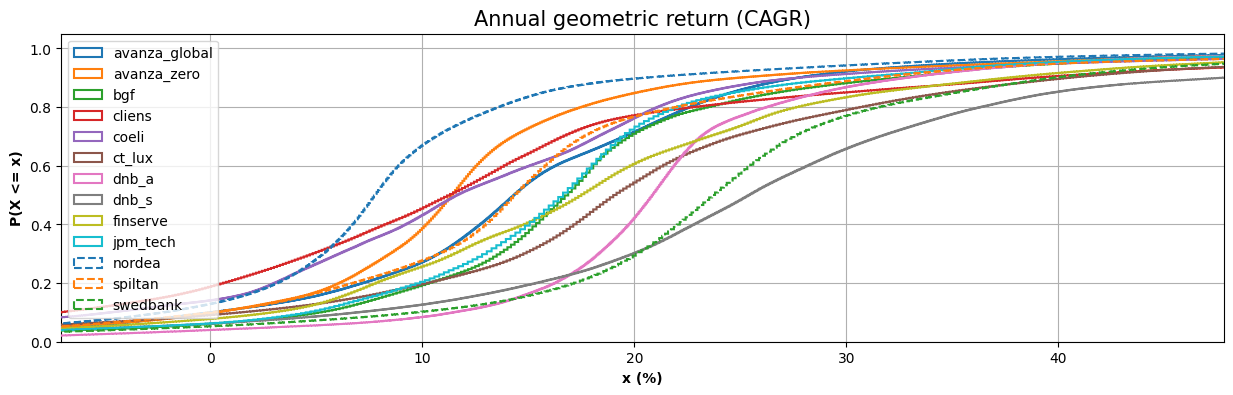

In [22]:
names = [
    "avanza_global",
    "avanza_zero",
    "bgf",
    "cliens",
    "coeli",
    "ct_lux",
    "dnb_a",
    "dnb_s",
    "finserve",
    "jpm_tech",
    "nordea",
    "spiltan",
    "swedbank",
]

fig, ax = plt.subplots(figsize=(15, 4))
xlims = []

color_cycler = cycle(COLORS)
color_counter = Counter()
for name in tqdm(names):
    data = df.query("name == @name")

    df_cagr = calc_cagr(data, min_days=30, timespan="annual")
    cagr_arr = df_cagr.values.flatten()
    cagr_arr = cagr_arr[~np.isnan(cagr_arr)]
    xlims.append(np.quantile(cagr_arr, [0.1, 0.9]))

    c = next(color_cycler)
    color_counter.update([c])
    linestyle = "--" if color_counter[c] > 1 else "-"
    ax.hist(
        cagr_arr,
        bins=10000,
        histtype="step",
        linewidth=1.5,
        linestyle=linestyle,
        cumulative=True,
        density=True,
        label=name,
        zorder=3,
    )
xlims = np.asarray(xlims)
ax.grid(zorder=1, which="both")
ax.legend()

xmin = xlims[:,0].min()
xmax = xlims[:,1].max()
ax.set_xlim(xmin, xmax)
ax.set_title("Annual geometric return (CAGR)", fontsize=15)
ax.set_ylabel("P(X <= x)", fontweight="bold")
ax.set_xlabel("x (%)", fontweight="bold")
plt.show()

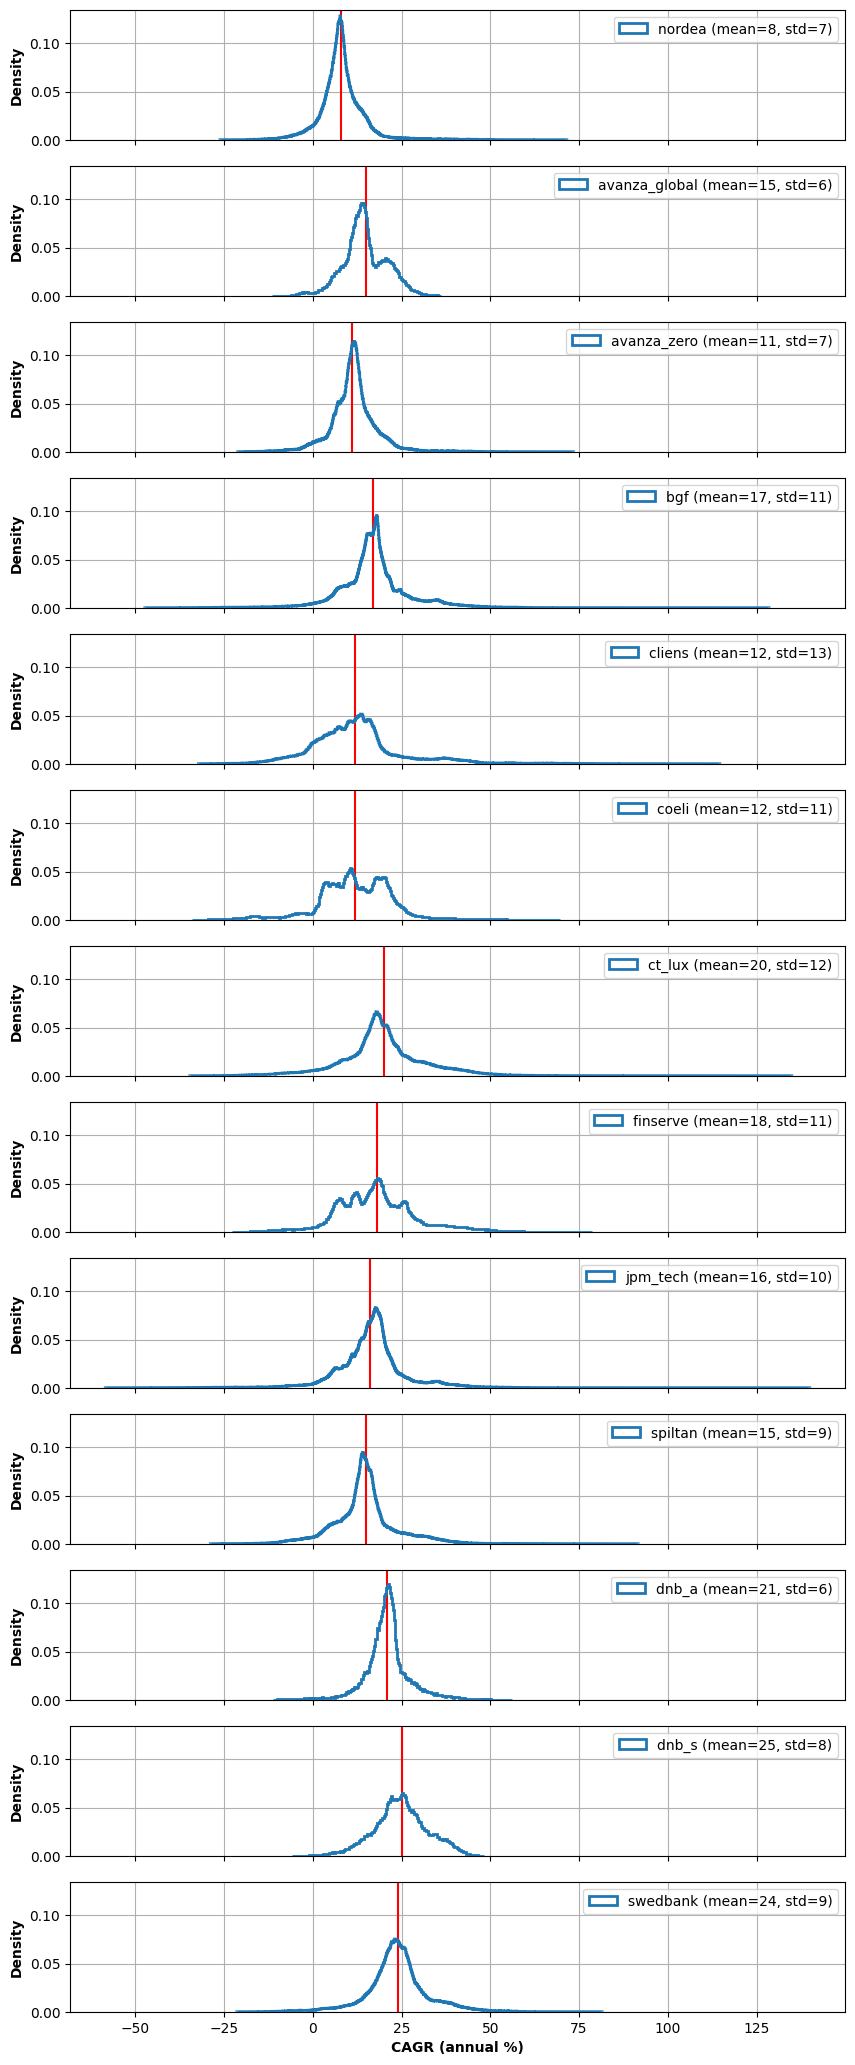

In [23]:
names = [
    "nordea",
    "avanza_global",
    "avanza_zero",
    "bgf",
    "cliens",
    "coeli",
    "ct_lux",
    "finserve",
    "jpm_tech",
    "spiltan",
    "dnb_a",
    "dnb_s",
    "swedbank",
]

nrows = len(names)
fig, axes = plt.subplots(nrows=nrows, ncols=1, figsize=(10, 2 * nrows), sharex=True, sharey=True)
xlims = []

color_cycler = cycle(COLORS)
color_counter = Counter()
for ax, name in tqdm(zip(axes, names)):
    data = df.query("name == @name")
    if data.empty:
        continue

    df_cagr = calc_cagr(data, min_days=365, timespan="annual")
    cagr_arr = df_cagr.values.flatten()
    cagr_arr = cagr_arr[~np.isnan(cagr_arr)]
    q1, q2 = np.quantile(cagr_arr, [0.01, 0.99])
    # cagr_arr = cagr_arr[(cagr_arr > q1) & (cagr_arr < q2)]
    mean = round(np.mean(cagr_arr))
    std = round(np.std(cagr_arr))

    c = next(color_cycler)
    color_counter.update([c])
    linestyle = "--" if color_counter[c] > 1 else "-"
    ax.hist(
        cagr_arr,
        bins="auto",
        histtype="step",
        linewidth=2,
        # linestyle=linestyle,
        cumulative=False,
        density=True,
        label=f"{name} (mean={mean}, std={std})",
        zorder=3,
    )
    ax.axvline(mean, color="r", zorder=2)
    ax.grid(zorder=1, which="both")
    ax.legend()
    if ax == axes[-1]:
        ax.set_xlabel("CAGR (annual %)", fontweight="bold")
    ax.set_ylabel("Density", fontweight="bold")
plt.show()

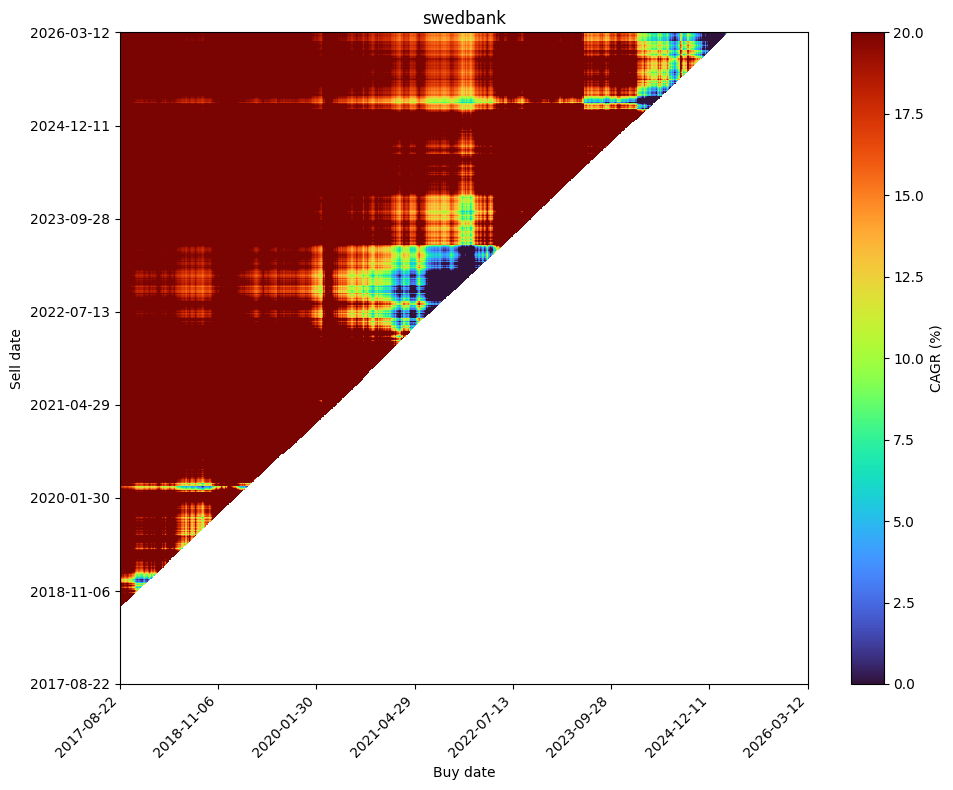

In [24]:
fig, ax = plt.subplots(figsize=(10, 8))

# y-axis = index (Sell), x-axis = columns (Buy)
im = ax.imshow(
    df_cagr.values,
    origin="lower",      # earlier dates at bottom
    aspect="auto",
    cmap="turbo",
    vmin=0,
    vmax=20,
    interpolation="none",
)

# Tick positions
n_x = len(df_cagr.columns)
n_y = len(df_cagr.index)
x_idx = np.linspace(0, n_x - 1, 8, dtype=int)
y_idx = np.linspace(0, n_y - 1, 8, dtype=int)

ax.set_xticks(x_idx)
ax.set_xticklabels(df_cagr.columns[x_idx].strftime("%Y-%m-%d"), rotation=45, ha="right")
ax.set_yticks(y_idx)
ax.set_yticklabels(df_cagr.index[y_idx].strftime("%Y-%m-%d"))

ax.set_xlabel("Buy date")
ax.set_ylabel("Sell date")
ax.set_title(f"{name}")
fig.colorbar(im, ax=ax, label="CAGR (%)")
plt.tight_layout()
plt.show()

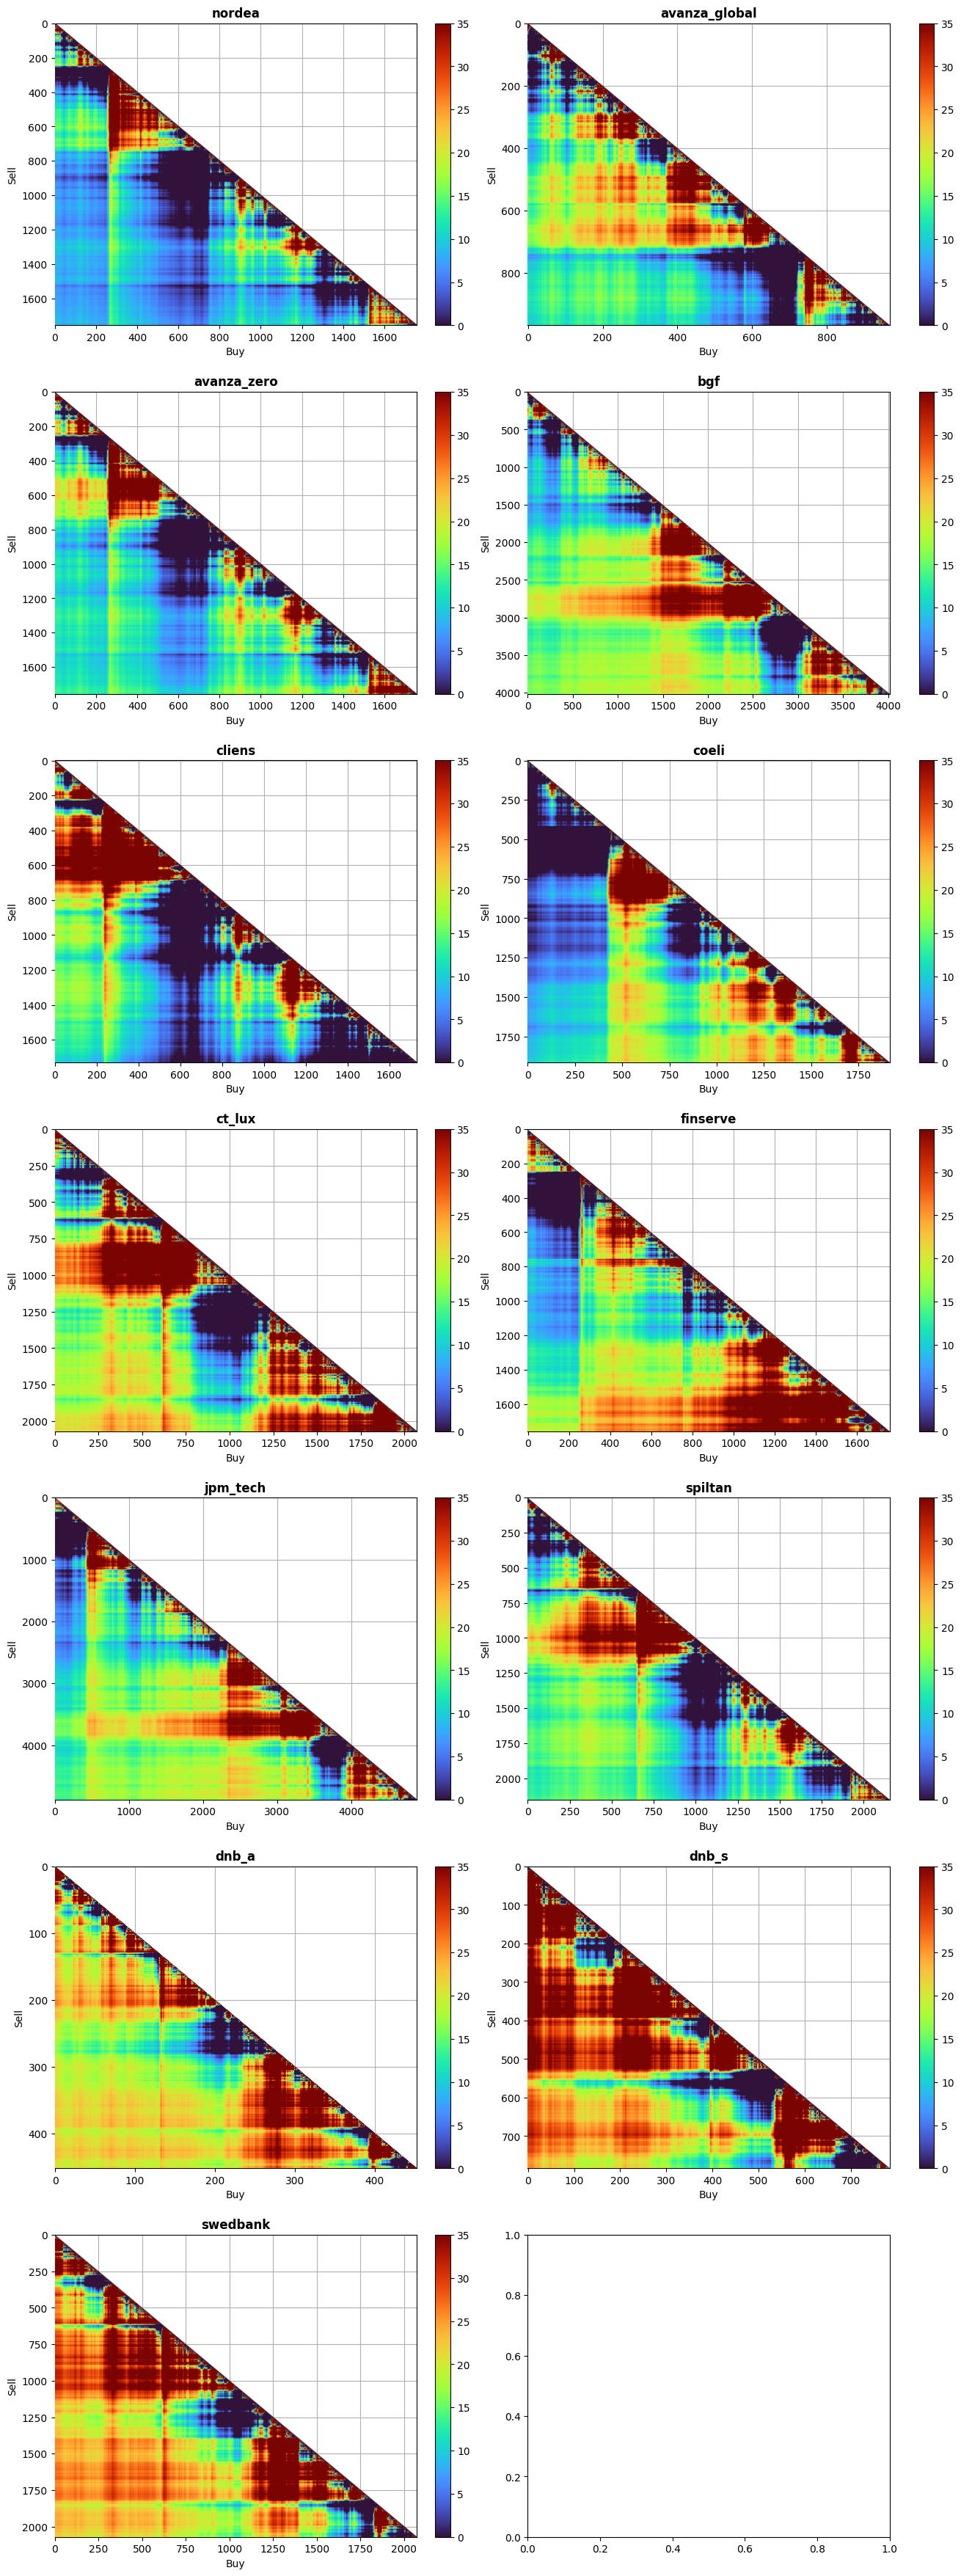

In [25]:
all_rates = {name: calc_cagr(df.query("name == @name").iloc[::1], min_days=0, timespan="annual") for name in names}

vmax = max([np.nanmax(r) for r in all_rates.values()])
vmin = max([np.nanmin(r) for r in all_rates.values()])
norm = colors.TwoSlopeNorm(vmin=0.8, vcenter=1.1, vmax=1.5)

ncols = 2
nrows = np.ceil(len(all_rates) / ncols).astype(int)
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(13, 5 * nrows),
    layout="constrained",
    gridspec_kw={"hspace": 0.05},
)
for ax, (name, R) in zip(axes.flatten(), all_rates.items()):
    im = ax.imshow(
        R,
        aspect="auto",
        cmap="turbo",
        vmin=0, vmax=35,
        zorder=5,
    )
    plt.colorbar(im, ax=ax)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Buy")
    ax.set_ylabel("Sell")
    ax.grid(zorder=1)
plt.show()

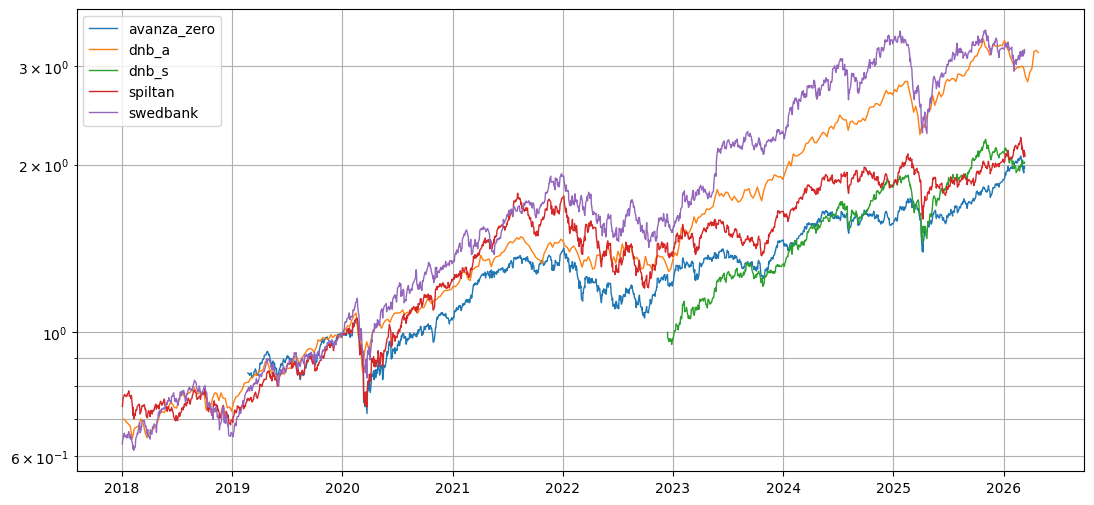

In [64]:
temp = df.pivot_table(index="date", columns="name", values="nav")
fig, ax = plt.subplots(figsize=(13, 6))
for name, col in temp.items():
    if name not in ["swedbank", "dnb_a", "dnb_s", "avanza_zero", "spiltan"]:
        continue
    col = col.dropna()
    col = col.loc[col.index > datetime(2018, 1, 1)]
    norm = col.loc[col.index > datetime(2020, 1, 1)].iloc[0].item()
    ax.semilogy(col.index, col.values / norm, zorder=3, label=name, linewidth=1)
ax.grid(zorder=1, which="both")
ax.legend()
plt.show()